# 08 — Phân tích khám phá (EDA): tổng quan, quy ước chung và kiểm tra độ nhạy

## Câu hỏi nghiên cứu (mục 1 của báo cáo)

> **Ô nhiễm không khí nặng (AQI từ 201 trở lên) tập trung ở thành phố nào và vào mùa nào trong 8 thành phố Ấn Độ giai đoạn 2015–2020, để cơ quan môi trường và người dân biết nên ưu tiên cảnh báo sức khỏe và giảm phát thải ở đâu, lúc nào?**

Ba câu hỏi phụ (phần chẩn đoán, chỉ nói "có liên quan", **không** nói "gây ra"):
1. Trong **cùng một thành phố**, ô nhiễm có giảm qua các năm không (so cùng các tháng 1–6)?
2. Khi AQI nặng, chất nào ở mức cao nhất?
3. Năm 2020 AQI thấp hơn 2019 cùng kỳ: mùa, xu hướng, lockdown, yếu tố nào có thể liên quan? (không kết luận nguyên nhân)

## Quy ước chung (cả nhóm dùng giống nhau, nếu không biểu đồ sẽ lệch nhau)

| Quy ước | Giá trị |
|---|---|
| Dữ liệu | `data/processed/air_quality_8cities.csv` (đã làm sạch, đã gộp) |
| So sánh giữa các thành phố | chỉ dùng **khoảng chung** (biến `win`), vì chuỗi mỗi thành phố dài ngắn khác nhau |
| "Nặng" | AQI **>= 201** (từ mức *Poor* trở lên theo thang CPCB). Tỉ lệ tính trên số ngày **có AQI** |
| Mùa | Đông (12-2), Hè (3-5), Mưa (6-9), Sau mưa (10-11) |
| Cột dùng làm biến | chỉ cột thiếu < 60% trong thành phố đó; PM10 và NH3 chỉ dùng có điều kiện (xem `Data_dictionary.md`) |
| Từ ngữ | "có liên quan", "đi cùng với". **Không** dùng "gây ra", "làm giảm" |

## Phân công (mỗi người một notebook riêng, nên không xung đột Git)

| Notebook | Người | Việc | Hình lưu ra |
|---|---|---|---|
| `08_eda.ipynb` (file này) | Delhi/Gurugram | Giữ quy ước chung, viết mục 1-3 báo cáo, ghép báo cáo, chạy lại toàn bộ lần cuối | `eda_00_*` |
| `08a_eda_o_dau.ipynb` | Lucknow/Jaipur | **Ở đâu**: bảng thống kê 4 họ, Biểu đồ 1, Biểu đồ 5 | `eda_01_*`, `eda_05_*` |
| `08b_eda_khi_nao.ipynb` | Bengaluru/Amritsar | **Khi nào**: Biểu đồ 2, Biểu đồ 3, chẩn đoán confounder | `eda_02_*`, `eda_03_*` |
| `08c_eda_chat_nao.ipynb` | Chennai/Hyderabad | **Chất nào**: Biểu đồ 4; sau đó tổng hợp mục 5 và mục 6, bộ câu vấn đáp | `eda_04_*` |

Mỗi notebook có bảng "phát hiện của phần này" ở cuối; người ghép báo cáo gom 3 bảng đó thành mục 5.

## Cách làm việc

- Mỗi người **chỉ sửa notebook của mình** và `git pull` trước khi push. Không sửa `src/eda_utils.py` nếu chưa báo cả nhóm.
- Mỗi biểu đồ: gọi `finish_chart(...)` rồi `save_fig(...)` (lưu vào `reports/figures/`).
- Trước khi push: **Kernel -> Restart & Run All** trong notebook của mình, không được lỗi (người chấm sẽ chạy đúng như vậy).
- Chỉ giữ **5 biểu đồ hoàn chỉnh** cho báo cáo; biểu đồ thử nghiệm thì xoá, đừng để 25 biểu đồ thô.

## Chuẩn biểu đồ (W7), tick đủ trước khi push

- [ ] Tiêu đề là **kết luận có con số** (không phải "AQI theo thành phố")
- [ ] Trục có **nhãn và đơn vị**
- [ ] Biểu đồ cột **bắt đầu từ 0**, sắp theo giá trị (không theo bảng chữ cái)
- [ ] **Một** màu nhấn cho điều muốn người đọc thấy, còn lại màu trung tính
- [ ] Ghi nhãn trực tiếp, bỏ legend nếu chỉ có một nhóm
- [ ] Không dùng biểu đồ tròn, 3D, trục kép; không dùng chỉ đỏ-xanh lá để phân biệt
- [ ] Thử chuyển sang thang xám vẫn đọc được
- [ ] Chú thích có cỡ mẫu và ngày dữ liệu (hàm `finish_chart` đã làm sẵn)

## 0. Setup

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eda_utils import (CITIES, USABLE, SEASON_ORDER, ACCENT, NEUTRAL,
                       vn, load, poor_share, four_families, finish_chart, save_fig, set_style)

set_style()
eda, win, START, END = load()      # eda: toàn bộ 2015-2020 | win: khoảng chung của 8 thành phố (dùng khi so sánh giữa thành phố)

Toàn bộ: 14.056 dòng, 01/01/2015 - 01/07/2020
Khoảng chung (biến win): 14/06/2017 - 01/07/2020, 8.912 dòng; 8.734 ngày có AQI


### Biểu đồ mẫu (đã đủ chuẩn W7, để tham chiếu cách gọi hàm)

Cũng dùng được trong báo cáo như bằng chứng về cỡ mẫu. Các notebook 08a, 08b, 08c làm cùng khuôn: cột ngang sắp theo giá trị, bắt đầu từ 0, một cột nhấn, nhãn trực tiếp, không legend.

Đã lưu reports/figures/eda_00_sample_size.png


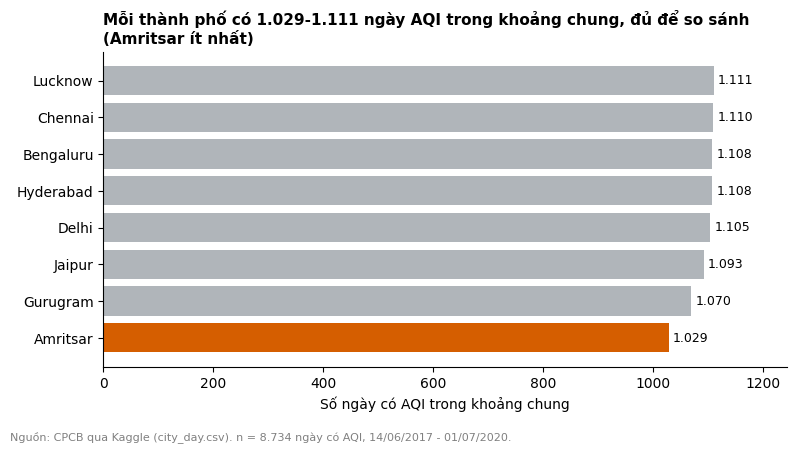

In [2]:
n_days = win.dropna(subset=["AQI"]).groupby("City", observed=True).size().sort_values()   # tăng dần để cột lớn nằm trên cùng

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(n_days.index.astype(str), n_days.values,
               color=[ACCENT if c == n_days.idxmin() else NEUTRAL for c in n_days.index])
ax.bar_label(bars, labels=[vn(v) for v in n_days.values], padding=3, fontsize=9)
ax.set_xlim(0, n_days.max() * 1.12)
ax.set_xlabel("Số ngày có AQI trong khoảng chung"); ax.set_ylabel("")
finish_chart(fig, ax, f"Mỗi thành phố có {vn(n_days.min())}-{vn(n_days.max())} ngày AQI trong khoảng chung, "
                      f"đủ để so sánh ({n_days.idxmin()} ít nhất)", win)
save_fig(fig, "00_sample_size")
plt.show()

## Kiểm tra độ nhạy (cho câu vấn đáp "nếu xoá ngẫu nhiên 10% số dòng, kết luận có đổi không?")

Bỏ ngẫu nhiên 10% số ngày, lặp 200 lần, xem **thứ hạng** các thành phố theo tỉ lệ ngày nặng có đổi không.
Kết quả: các cặp có tỉ lệ gần nhau (Lucknow và Gurugram; Amritsar và Jaipur; Bengaluru và Hyderabad) hay đổi chỗ, nên trong báo cáo **chia theo nhóm** thay vì xếp hạng từng thành phố.

In [3]:
def share(d):                                      # không làm tròn, để thứ hạng không bị hòa giả do làm tròn
    return d.dropna(subset=["AQI"]).groupby("City", observed=True).poor.mean() * 100

rng = np.random.default_rng(42)
base = share(win)
runs = pd.DataFrame([share(win.sample(frac=0.9, random_state=int(rng.integers(1e9)))) for _ in range(200)])
stable = (runs.rank(axis=1, ascending=False) == base.rank(ascending=False)).mean() * 100
sens = pd.DataFrame({"pct_poor_goc": base.round(1), "nho_nhat": runs.min().round(1), "lon_nhat": runs.max().round(1),
                     "thu_hang_giu_nguyen_%": stable.round(0)}).sort_values("pct_poor_goc", ascending=False)
sens

,pct_poor_goc,nho_nhat,lon_nhat,thu_hang_giu_nguyen_%
City,,,,
Delhi,51.0,49.3,53.1,100.0
Lucknow,46.4,45.0,47.7,59.0
Gurugram,46.3,44.6,48.2,59.0
Amritsar,11.4,10.5,12.2,76.0
Jaipur,11.1,10.0,11.8,76.0
Chennai,3.1,2.6,3.4,100.0
Bengaluru,0.2,0.0,0.2,93.0
Hyderabad,0.1,0.0,0.1,93.0


## Câu hỏi vấn đáp đã công bố trước (W8), mỗi người đều phải trả lời được

1. Vì sao xử lý missing theo cách đó? (xem `reports/cleaning_log_report_8cities.csv`)
2. Cơ chế thiếu của cột này là gì, bằng chứng nào? (dòng về cột thiếu >= 20% trong nhật ký)
3. Nếu xoá ngẫu nhiên 10% dòng, kết luận có đổi không? (bảng kiểm tra độ nhạy ở trên)
4. Biểu đồ này có thể đánh lừa người đọc vội ở chỗ nào?
5. **Confounder hợp lý cho quan hệ vừa mô tả là gì?** (câu quyết định điểm diễn giải)

Câu hỏi riêng của đề tài nên chuẩn bị thêm: vì sao dùng khoảng chung? vì sao ngưỡng 201? vì sao tháng 1-6 khi so các năm? vì sao PM10/NH3 không dùng làm biến?

## Ghép báo cáo (người ghép)

1. Mục 4: lấy 5 hình `eda_01`, `eda_02`, `eda_03`, `eda_04`, `eda_05` trong `reports/figures/` (và `eda_00` nếu cần chứng minh cỡ mẫu).
2. Mục 5: gom 3 bảng "phát hiện của phần này" từ 08a, 08b, 08c, mỗi ý gắn một biểu đồ.
3. Mục 6: lấy từ phần tổng hợp cuối `08c`.
4. Chạy lại **08 -> 08a -> 08b -> 08c** bằng Restart & Run All trước khi nộp.